In [ ]:
import torch
import torchvision
import matplotlib.pyplot as plt

from PIL import Image
from src.models import *
from src.utils import *
from src.vision_transformer import VisionTransformer, vit_tiny, vit_small, vit_base, vit_large

In [2]:
if torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')

torch.manual_seed(0)

transform = torchvision.transforms.Compose([torchvision.transforms.Resize((224,224)),
                            torchvision.transforms.ToTensor()])

In [9]:
pil_img1 = Image.open('./test_images/test_image10.JPEG').convert('RGB')
pil_img2 = Image.open('./test_images/Fish3.JPEG').convert('RGB')

img1 = transform(pil_img1)
img2 = transform(pil_img2)

x1 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img1)
x2 = torchvision.transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img2)

x1 = x1[None,...].to(device)
x2 = x2[None,...].to(device)

In [18]:
architectures = ['ibot']
p = []

for architecture in architectures:

    if architecture == 'VGG-16':
        model = VGG_emb(level='full')
        model = model.to(device)
        model.eval()
    elif architecture == 'ResNET-50':
        model = ResNET_emb(level='full')
        model = model.to(device)
        model.eval()
    elif architecture == 'ViTb-16':
        model = ViT16_emb()
        model = model.to(device)
        model.eval()
    elif architecture == 'Dino':
        model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14')
        model = model.to(device)
        model.eval()

    elif architecture == 'DINOv1':
        model = torch.hub.load('facebookresearch/dino:main', 'dino_resnet50')
        model = model.to(device)
        model.eval()
    
    elif architecture == 'SwAV':     
        model = torch.hub.load('facebookresearch/swav:main', 'resnet50w2')
        model = model.to(device)
        model.eval()
        
    elif architecture == 'Barlow Twins':     
        model = torch.hub.load('facebookresearch/barlowtwins:main', 'resnet50')
        model = model.to(device)
        model.eval()
        
    # s,h = compute_saliency(x=x1, x_target=x1, model=model, n_masks=20, epochs=20, beta=20, return_negative=False, learnable_param=True)
    # # s = compute_saliency(x=x1, x_target=x1, model=model, n_masks=20, epochs=20, beta=20, return_negative=False, learnable_param=True)
    # p.append(s)
    p.append(model)
    # del model

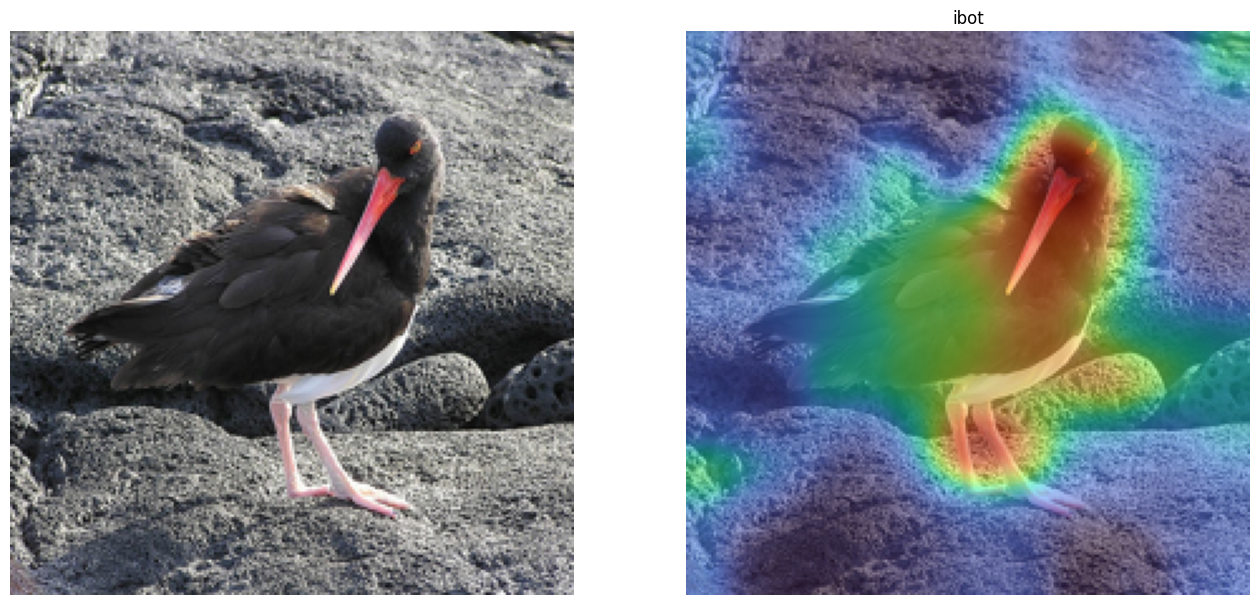

<Figure size 640x480 with 0 Axes>

In [6]:
f, ax = plt.subplots(1,len(p)+1, figsize=(16,20))

cm = 'turbo'
alph = 0.6

ax[0].imshow(pil_img1.resize((224,224)))
ax[0].axis('off')

for i,architecture in enumerate(architectures):

    ax[i+1].imshow(pil_img1.resize((224,224)))
    ax[i+1].imshow(p[i], cmap=cm, alpha=alph)
    ax[i+1].title.set_text(architecture)
    ax[i+1].axis('off')

plt.show()
plt.savefig('bla.png')

In [7]:
# h = np.array(h)
# mean_beta = np.mean(h[:,0,:], axis=0)
# mean_phi = np.mean(h[:,1,:], axis=0)

# std_beta = np.std(h[:,0,:], axis=0)
# std_phi = np.std(h[:,1,:], axis=0)

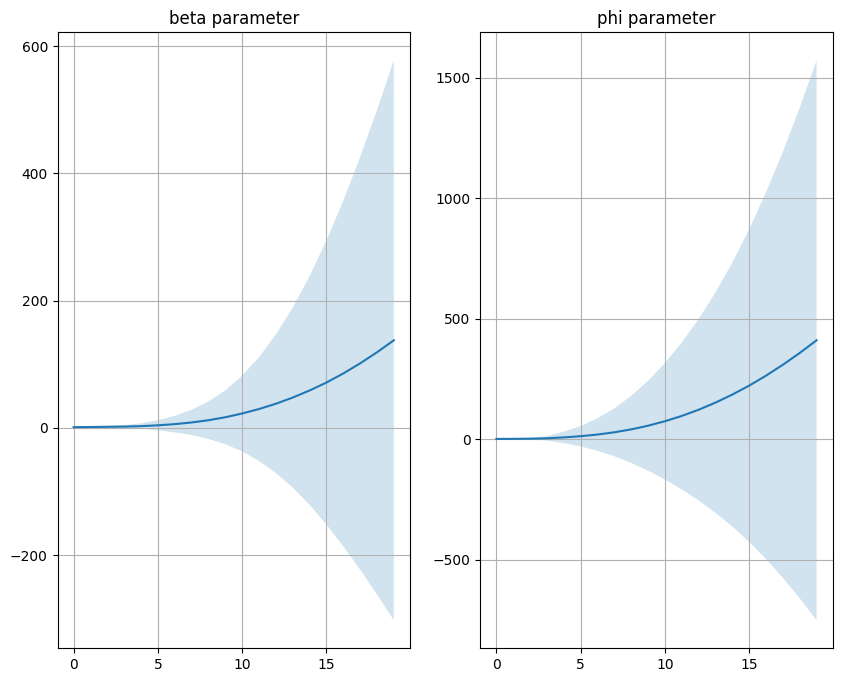

In [9]:
# f, ax = plt.subplots(1,2, figsize=(10,8))

ax[0].plot(np.arange(20), mean_beta)
ax[0].fill_between(np.arange(20), mean_beta + std_beta, mean_beta - std_beta, alpha=0.2)
ax[0].grid()
ax[0].title.set_text("beta parameter")


ax[1].plot(np.arange(20), mean_phi)
ax[1].fill_between(np.arange(20), mean_phi + std_phi, mean_phi - std_phi, alpha=0.2)
ax[1].grid()
ax[1].title.set_text("phi parameter")

# plt.show()

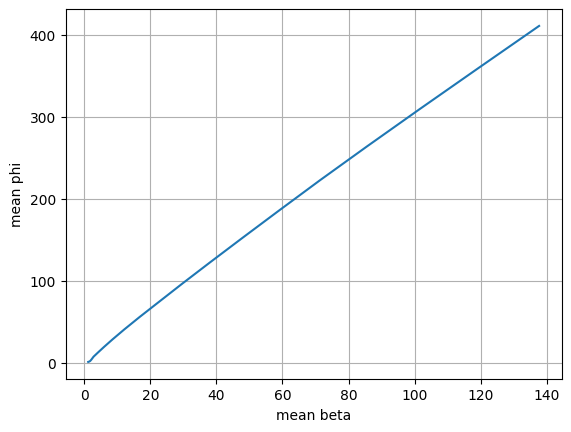

In [10]:
plt.plot(mean_beta, mean_phi)
plt.xlabel("mean beta")
plt.ylabel("mean phi")
plt.grid()
plt.show()

In [ ]:
# levels = [1,2,3,'full']
# p = []

# f, ax = plt.subplots(1,4, figsize=(16,20))

# cm = 'Reds'
# alph = 0.5

# for i,level in enumerate(levels):
#     model = VGG_emb(level=level)
#     model = model.to(device)
#     model.eval()

#     p.append(compute_saliency(x=x1, x_target=x1, model=model, n_masks=20, beta=1, return_negative=False))

#     ax[i].imshow(pil_img1.resize((224,224)))
#     ax[i].imshow(p[i], cmap=cm, alpha=alph)
#     ax[i].title.set_text(str(level))
#     ax[i].axis('off')

#     del model

In [ ]:
# model = ViT16_emb()
# model = model.to(device)
# model.eval()

# betas = [1,10, 100]
# p = []

# for i,beta in enumerate(betas):
#     p.append(compute_saliency(x=x1, x_target=x1, model=model, n_masks=20, beta=beta, return_negative=False))

In [ ]:
# f, ax = plt.subplots(1,len(betas)+1, figsize=(16,20))
# ax[0].imshow(pil_img1.resize((224,224)))
# ax[0].axis('off')

# cm = 'viridis'
# alph = 0.6

# for i,beta in enumerate(betas):

#     ax[i+1].imshow(pil_img1.resize((224,224)))
#     ax[i+1].imshow(p[i], cmap=cm, alpha=alph)
#     ax[i+1].title.set_text(r'$\beta$ = ' + str(beta) + '/k')
#     ax[i+1].axis('off')